# Financial sentiment analysis: classical ML vs. BiLSTM

Classifies financial news sentences as **positive**, **neutral** or **negative** and compares five models:

| Representation | Classifier |
|---|---|
| Bag-of-Words (unigrams + bigrams) | Logistic Regression, linear SVM |
| TF-IDF (unigrams + bigrams) | Logistic Regression, linear SVM |
| Word2Vec-initialised embeddings | Bidirectional LSTM |

Joint project with Alessia Lecchi and Giacomo Pagani, *Artificial Intelligence* course, MSc in Analytics and Data Science for Economics and Management, University of Brescia.

The notebook runs end to end on a CPU in about 10–20 minutes. All random seeds are fixed (`RANDOM_STATE = 42`).

In [1]:
import os
import re
import pickle
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import ftfy
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

from gensim.models import Word2Vec

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(pkg, quiet=True)

# Reproducibility
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)
tf.config.experimental.enable_op_determinism()

os.makedirs("figures", exist_ok=True)
os.makedirs("models", exist_ok=True)

## 1. Data

The dataset combines two public sources of labelled financial text (see the README):
the **Financial PhraseBank** (Malo et al., 2014) and a large compilation of financial news headlines.
Duplicated sentences are removed first.

In [2]:
original = pd.read_csv("data/financial_sentiment.csv")
print(f"Rows: {len(original)}")

dataset_unique = (original
                  .drop_duplicates(subset="sentence", keep="first")
                  .reset_index(drop=True))
print(f"Rows after duplicate removal: {len(dataset_unique)}")

label_counts = dataset_unique["sentiment"].value_counts()
print(pd.DataFrame({"count": label_counts,
                    "share (%)": (label_counts / label_counts.sum() * 100).round(2)}))
print("\nImbalance ratio vs. smallest class:")
print((label_counts / label_counts.min()).round(2))

Rows: 35782
Rows after duplicate removal: 33283
           count  share (%)
sentiment                  
positive   13426      40.34
neutral    12219      36.71
negative    7638      22.95

Imbalance ratio vs. smallest class:
sentiment
positive    1.76
neutral     1.60
negative    1.00
Name: count, dtype: float64


### 1.1 Balancing and train / validation / test split

Positive and neutral sentences are undersampled to 8,000 each, keeping all negative sentences,
so that the three classes are almost balanced. The data are then split 70 / 15 / 15, stratified by class.
The validation set is used only for early stopping of the BiLSTM; all models are compared on the same test set.

In [3]:
positive_df = dataset_unique[dataset_unique["sentiment"] == "positive"]
neutral_df  = dataset_unique[dataset_unique["sentiment"] == "neutral"]
negative_df = dataset_unique[dataset_unique["sentiment"] == "negative"]

dataset_balanced = (pd.concat([positive_df.sample(n=8000, random_state=RANDOM_STATE),
                               neutral_df.sample(n=8000, random_state=RANDOM_STATE),
                               negative_df])
                    .sample(frac=1, random_state=RANDOM_STATE)
                    .reset_index(drop=True))
print(dataset_balanced["sentiment"].value_counts())

sentences  = dataset_balanced["sentence"].to_numpy()
sentiments = dataset_balanced["sentiment"].to_numpy()

# 85% train+validation / 15% test
temp_sentences, test_sentences, temp_labels, test_labels = train_test_split(
    sentences, sentiments, test_size=0.15, random_state=RANDOM_STATE, stratify=sentiments)

# 70% train / 15% validation
train_sentences, val_sentences, train_labels, val_labels = train_test_split(
    temp_sentences, temp_labels, test_size=0.17647, random_state=RANDOM_STATE, stratify=temp_labels)

for name, y in [("Train", train_labels), ("Validation", val_labels), ("Test", test_labels)]:
    print(f"{name:<11}", len(y), dict(pd.Series(y).value_counts()))

sentiment
positive    8000
neutral     8000
negative    7638
Name: count, dtype: int64
Train       16546 {'positive': np.int64(5600), 'neutral': np.int64(5600), 'negative': np.int64(5346)}
Validation  3546 {'positive': np.int64(1200), 'neutral': np.int64(1200), 'negative': np.int64(1146)}
Test        3546 {'neutral': np.int64(1200), 'positive': np.int64(1200), 'negative': np.int64(1146)}


## 2. Text preprocessing

A shared cleaning step (encoding fixes, URLs, mentions, tickers, hashtags, emoticons) is followed by
**two model-specific pipelines**, because the two families of models rely on different assumptions:

- **A) classical ML (BoW / TF-IDF):** lowercase, alphabetic tokens only, stopword removal
  (keeping the negations *no*, *not*, *but*), lemmatisation;
- **B) deep learning (BiLSTM):** lowercase and alphabetic tokens only, with no stopword removal
  or lemmatisation, so that word order and function words are preserved.

In [4]:
def clean_sentence(sentence):
    sentence = ftfy.fix_text(sentence)
    sentence = re.sub(r"http\S+|www\S+", "", sentence)   # URLs
    sentence = re.sub(r"@\w+", "", sentence)              # mentions
    sentence = re.sub(r"\$\w+", "", sentence)             # cashtags
    sentence = re.sub(r"\(\w+:\w+\)", "", sentence)       # (NYSE:XYZ)
    sentence = re.sub(r"#\w+", "", sentence)              # hashtags
    sentence = re.sub(r"[\|–—…]", "", sentence)
    sentence = re.sub(r"[:;=8][\-~]?[)DPO]", "", sentence)  # emoticons
    return sentence.strip()

train_clean = np.array([clean_sentence(s) for s in train_sentences])
val_clean   = np.array([clean_sentence(s) for s in val_sentences])
test_clean  = np.array([clean_sentence(s) for s in test_sentences])

# A) classical ML pipeline
stop_words = set(stopwords.words("english")) - {"no", "not", "but"}
lemmatizer = WordNetLemmatizer()

def preprocess_ml(text):
    tokens = nltk.word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha() and t not in stop_words]
    return " ".join(lemmatizer.lemmatize(t) for t in tokens)

# B) deep-learning pipeline
def preprocess_dl(text):
    tokens = nltk.word_tokenize(text.lower())
    return " ".join(t for t in tokens if t.isalpha())

train_ml = np.array([preprocess_ml(s) for s in train_clean])
val_ml   = np.array([preprocess_ml(s) for s in val_clean])
test_ml  = np.array([preprocess_ml(s) for s in test_clean])

train_dl = np.array([preprocess_dl(s) for s in train_clean])
val_dl   = np.array([preprocess_dl(s) for s in val_clean])
test_dl  = np.array([preprocess_dl(s) for s in test_clean])

print("Original:", train_sentences[0])
print("ML:      ", train_ml[0])
print("DL:      ", train_dl[0])

Original: UnitedHealth stock price target raised to $338 from $303 at CFRA
ML:       unitedhealth stock price target raised cfra
DL:       unitedhealth stock price target raised to from at cfra


## 3. Text representation

### 3.1 Bag-of-Words and TF-IDF

Both use unigrams and bigrams. TF-IDF additionally filters very rare (`min_df=5`) and very frequent
(`max_df=0.9`) terms and uses sublinear term frequency, which gives a much more compact vocabulary.

In [5]:
cv = CountVectorizer(ngram_range=(1, 2))
cv_train = cv.fit_transform(train_ml)
cv_test  = cv.transform(test_ml)

tfidf = TfidfVectorizer(min_df=5, max_df=0.9, ngram_range=(1, 2), sublinear_tf=True)
tfidf_train = tfidf.fit_transform(train_ml)
tfidf_test  = tfidf.transform(test_ml)

print("BoW    train matrix:", cv_train.shape)
print("TF-IDF train matrix:", tfidf_train.shape)

BoW    train matrix: (16546, 142078)
TF-IDF train matrix: (16546, 8277)


### 3.2 Word2Vec embeddings for the BiLSTM

Sentences from the deep-learning pipeline are converted to padded sequences of length 100.
A skip-gram Word2Vec model (200 dimensions) is trained on the training set only, and its vectors
initialise the embedding layer of the BiLSTM.

In [6]:
SENTIMENT_MAP = {"negative": 0, "neutral": 1, "positive": 2}
CLASS_NAMES = ["negative", "neutral", "positive"]

y_train = to_categorical([SENTIMENT_MAP[s] for s in train_labels], num_classes=3)
y_val   = to_categorical([SENTIMENT_MAP[s] for s in val_labels],   num_classes=3)
y_test  = to_categorical([SENTIMENT_MAP[s] for s in test_labels],  num_classes=3)

MAX_WORDS, MAX_LEN, EMBEDDING_DIM = 10_000, 100, 200

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(train_dl)                      # fit on training data only

def to_padded(texts):
    return pad_sequences(tokenizer.texts_to_sequences(texts),
                         maxlen=MAX_LEN, padding="post", truncating="post")

padded_train, padded_val, padded_test = map(to_padded, [train_dl, val_dl, test_dl])
print("Padded training sequences:", padded_train.shape)

w2v = Word2Vec(sentences=[doc.split() for doc in train_dl],
               vector_size=EMBEDDING_DIM, window=5, min_count=3, sg=1, epochs=10,
               workers=1, seed=RANDOM_STATE)        # workers=1 for reproducibility

embedding_matrix = np.zeros((MAX_WORDS, EMBEDDING_DIM))
covered = 0
for word, idx in tokenizer.word_index.items():
    if idx < MAX_WORDS and word in w2v.wv:
        embedding_matrix[idx] = w2v.wv[word]
        covered += 1
n_vocab = min(MAX_WORDS, len(tokenizer.word_index))
print(f"Word2Vec vocabulary: {len(w2v.wv)} words | embedding coverage: {covered}/{n_vocab} "
      f"({covered / n_vocab:.1%})")

Padded training sequences: (16546, 100)


Word2Vec vocabulary: 7720 words | embedding coverage: 7720/10000 (77.2%)


## 4. Classical machine learning

In [7]:
def evaluate(name, y_true, y_pred):
    return {"Model": name,
            "Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, average="weighted"),
            "Recall":    recall_score(y_true, y_pred, average="weighted"),
            "F1":        f1_score(y_true, y_pred, average="weighted")}

classical = {
    "LR + BoW":     (LogisticRegression(C=1, max_iter=1000), cv_train, cv_test),
    "LR + TF-IDF":  (LogisticRegression(C=1, max_iter=1000), tfidf_train, tfidf_test),
    "SVM + BoW":    (SGDClassifier(loss="hinge", max_iter=1000, random_state=RANDOM_STATE), cv_train, cv_test),
    "SVM + TF-IDF": (SGDClassifier(loss="hinge", max_iter=1000, random_state=RANDOM_STATE), tfidf_train, tfidf_test),
}

predictions, results = {}, []
for name, (clf, X_tr, X_te) in classical.items():
    clf.fit(X_tr, train_labels)
    predictions[name] = clf.predict(X_te)
    results.append(evaluate(name, test_labels, predictions[name]))
    print(f"=== {name} ===")
    print(classification_report(test_labels, predictions[name], digits=3))

=== LR + BoW ===
              precision    recall  f1-score   support

    negative      0.726     0.712     0.719      1146
     neutral      0.725     0.798     0.760      1200
    positive      0.705     0.647     0.675      1200

    accuracy                          0.719      3546
   macro avg      0.719     0.719     0.718      3546
weighted avg      0.719     0.719     0.718      3546



=== LR + TF-IDF ===
              precision    recall  f1-score   support

    negative      0.704     0.692     0.698      1146
     neutral      0.724     0.781     0.751      1200
    positive      0.680     0.638     0.659      1200

    accuracy                          0.704      3546
   macro avg      0.703     0.704     0.703      3546
weighted avg      0.703     0.704     0.703      3546

=== SVM + BoW ===


              precision    recall  f1-score   support

    negative      0.731     0.697     0.714      1146
     neutral      0.725     0.800     0.760      1200
    positive      0.704     0.662     0.682      1200

    accuracy                          0.720      3546
   macro avg      0.720     0.720     0.719      3546
weighted avg      0.720     0.720     0.719      3546

=== SVM + TF-IDF ===
              precision    recall  f1-score   support

    negative      0.702     0.705     0.704      1146
     neutral      0.723     0.782     0.751      1200
    positive      0.691     0.632     0.660      1200

    accuracy                          0.706      3546
   macro avg      0.705     0.706     0.705      3546
weighted avg      0.705     0.706     0.705      3546



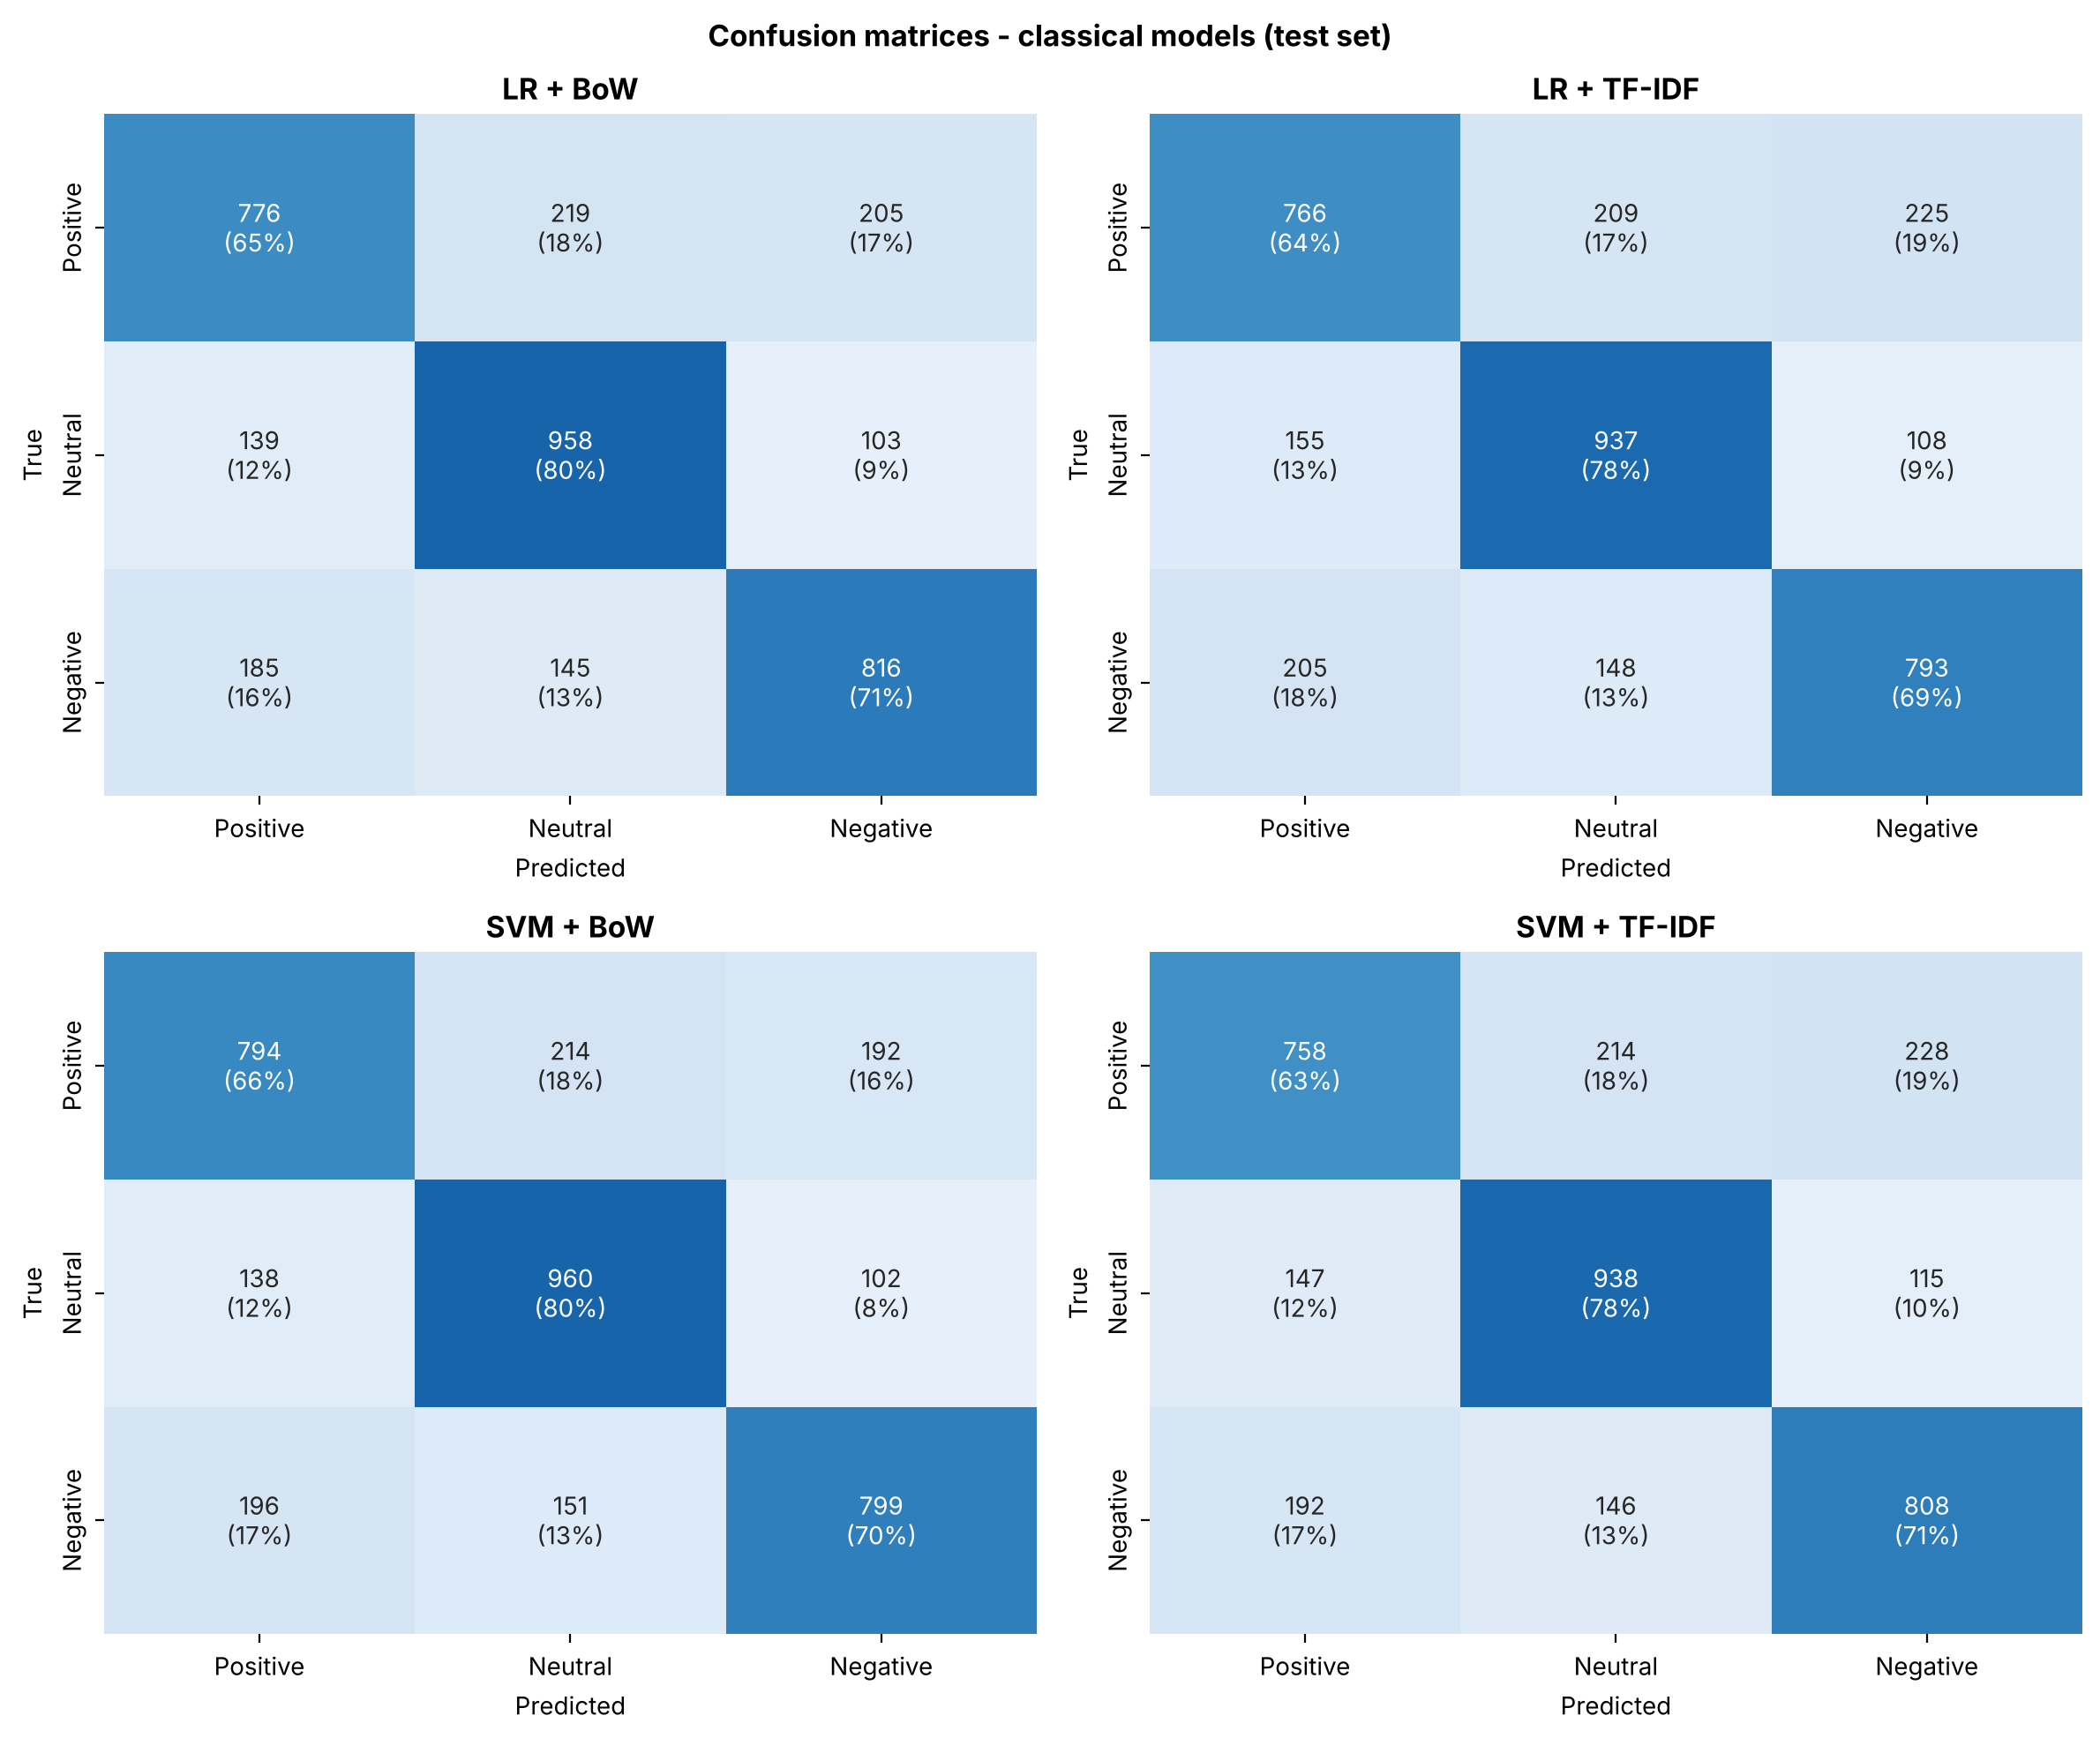

In [8]:
LABELS = ["positive", "neutral", "negative"]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, preds) in zip(axes.flatten(), predictions.items()):
    cm = confusion_matrix(test_labels, preds, labels=LABELS)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    annot = [[f"{cm[i, j]}\n({cm_norm[i, j]:.0%})" for j in range(3)] for i in range(3)]
    sns.heatmap(cm_norm, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=[l.capitalize() for l in LABELS],
                yticklabels=[l.capitalize() for l in LABELS], ax=ax)
    ax.set_title(name, fontweight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
fig.suptitle("Confusion matrices - classical models (test set)", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/confusion_matrices_classical.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Deep learning: Bidirectional LSTM

One bidirectional LSTM layer (64 units per direction) on top of the Word2Vec-initialised embedding layer,
which is fine-tuned during training. Dropout and early stopping on the validation loss limit overfitting.
A deeper, two-layer BiLSTM was also tried during the project but overfitted more without improving accuracy.

In [9]:
model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(MAX_WORDS, EMBEDDING_DIM,
              embeddings_initializer=tf.keras.initializers.Constant(embedding_matrix),
              trainable=True),
    Bidirectional(LSTM(64, recurrent_dropout=0.2)),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(3, activation="softmax"),
])
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 200)       │     2,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │       135,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,144,131 (8.18 MB)

 Trainable params: 2,144,131 (8.18 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1),
]

history = model.fit(padded_train, y_train,
                    validation_data=(padded_val, y_val),
                    epochs=10, batch_size=64, callbacks=callbacks, verbose=2)

Epoch 1/10


259/259 - 36s - 138ms/step - accuracy: 0.5800 - loss: 0.8891 - val_accuracy: 0.6760 - val_loss: 0.7566 - learning_rate: 0.0010


Epoch 2/10


259/259 - 32s - 124ms/step - accuracy: 0.7216 - loss: 0.6772 - val_accuracy: 0.7064 - val_loss: 0.7024 - learning_rate: 0.0010


Epoch 3/10


259/259 - 40s - 154ms/step - accuracy: 0.8036 - loss: 0.5215 - val_accuracy: 0.6920 - val_loss: 0.7557 - learning_rate: 0.0010


... (7 outputs left out)

Epoch 7/10


259/259 - 34s - 132ms/step - accuracy: 0.9325 - loss: 0.2012 - val_accuracy: 0.6960 - val_loss: 1.1188 - learning_rate: 5.0000e-04


Epoch 7: early stopping


Restoring model weights from the end of the best epoch: 2.


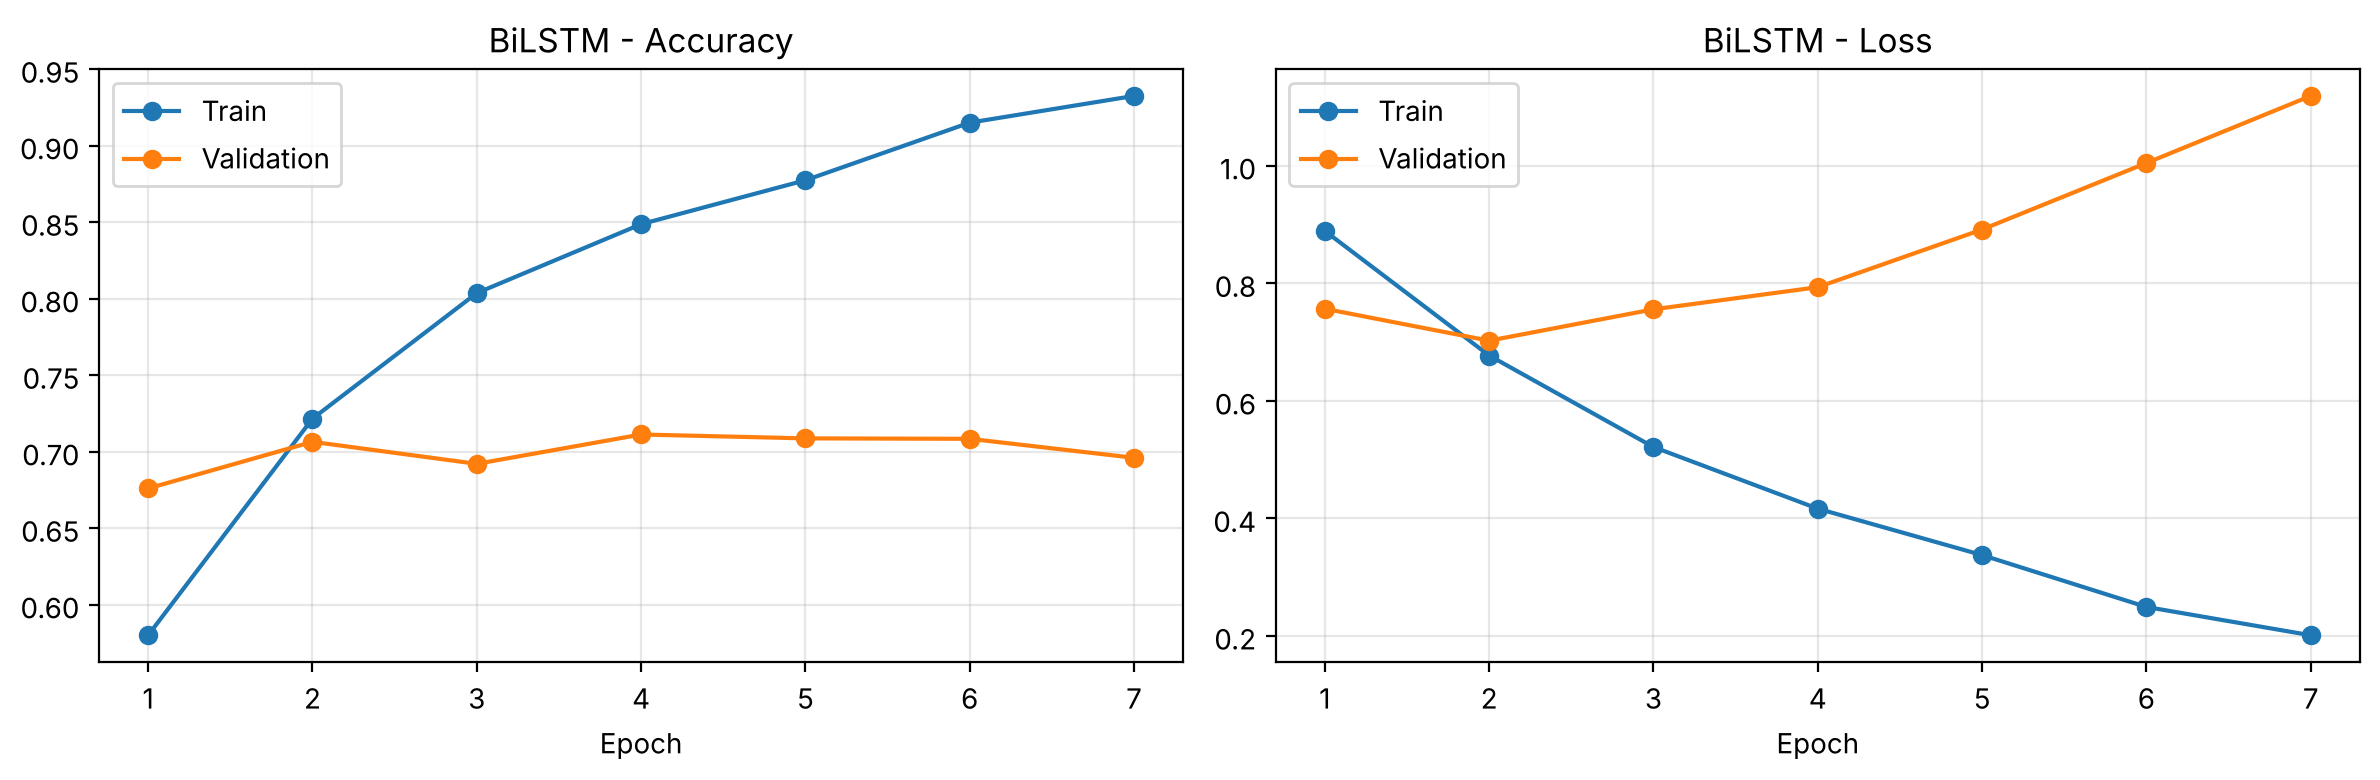

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
epochs = range(1, len(history.history["loss"]) + 1)
for ax, metric, title in [(ax1, "accuracy", "Accuracy"), (ax2, "loss", "Loss")]:
    ax.plot(epochs, history.history[metric], marker="o", label="Train")
    ax.plot(epochs, history.history[f"val_{metric}"], marker="o", label="Validation")
    ax.set_title(f"BiLSTM - {title}")
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/bilstm_training.png", dpi=150, bbox_inches="tight")
plt.show()

Training accuracy keeps rising while validation loss starts increasing after the first epochs:
the network overfits quickly, and early stopping restores the weights of the best validation epoch.

In [12]:
y_pred_probs = model.predict(padded_test, verbose=0)
bilstm_pred = np.array(CLASS_NAMES)[y_pred_probs.argmax(axis=1)]

predictions["BiLSTM (W2V)"] = bilstm_pred
results.append(evaluate("BiLSTM (W2V)", test_labels, bilstm_pred))
print(classification_report(test_labels, bilstm_pred, digits=3))

              precision    recall  f1-score   support

    negative      0.714     0.691     0.702      1146
     neutral      0.765     0.722     0.743      1200
    positive      0.674     0.733     0.703      1200

    accuracy                          0.716      3546
   macro avg      0.718     0.715     0.716      3546
weighted avg      0.718     0.716     0.716      3546



## 6. Model comparison

In [13]:
report_df = (pd.DataFrame(results)
             .sort_values("F1", ascending=False)
             .reset_index(drop=True)
             .round(4))
report_df.to_csv("figures/model_comparison.csv", index=False)
report_df

,Model,Accuracy,Precision,Recall,F1
0,SVM + BoW,0.7200,0.7196,0.7200,0.7188
1,LR + BoW,0.7191,0.7186,0.7191,0.7178
2,BiLSTM (W2V),0.7157,0.7179,0.7157,0.7161
3,SVM + TF-IDF,0.7061,0.7053,0.7061,0.7049
4,LR + TF-IDF,0.7039,0.7029,0.7039,0.7028


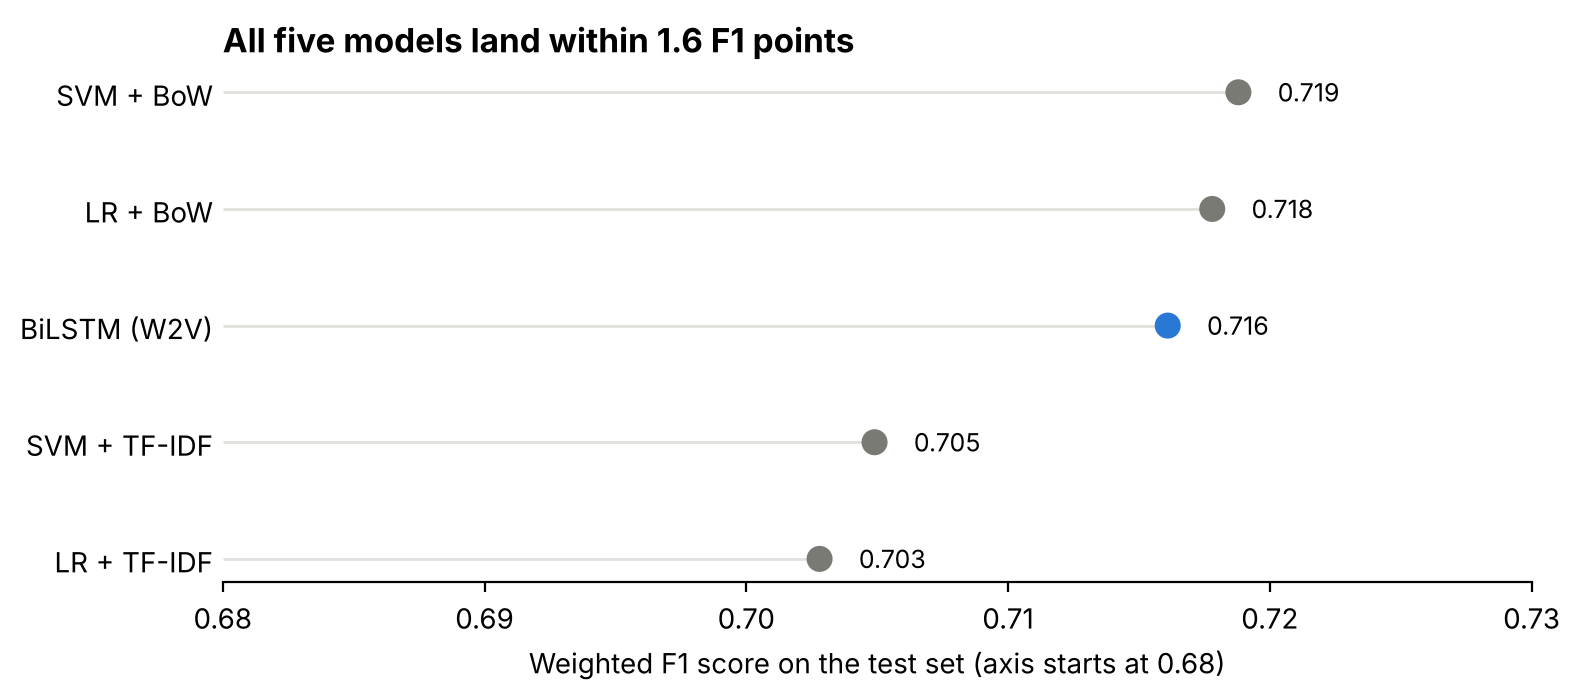

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.6))
order = report_df.sort_values("F1")
colors = ["#2a78d6" if "BiLSTM" in m else "#7a7a75" for m in order["Model"]]
ax.hlines(order["Model"], 0.68, order["F1"], color="#e1e0dc", lw=1)
ax.scatter(order["F1"], order["Model"], color=colors, s=70, zorder=3)
for y, v in enumerate(order["F1"]):
    ax.text(v + 0.0015, y, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0.68, 0.73)
ax.set_xlabel("Weighted F1 score on the test set (axis starts at 0.68)")
ax.set_title("All five models land within 1.6 F1 points", loc="left", fontweight="bold")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.savefig("figures/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Error analysis and predictions on new sentences

In [15]:
rng = np.random.default_rng(RANDOM_STATE)
for idx in rng.choice(len(test_sentences), size=8, replace=False):
    true, pred = test_labels[idx], bilstm_pred[idx]
    probs = ", ".join(f"{c}: {p:.0%}" for c, p in zip(CLASS_NAMES, y_pred_probs[idx]))
    print(f"{'OK   ' if true == pred else 'WRONG'} | true: {true:<8} | predicted: {pred:<8} | {probs}")
    print(f"      {test_sentences[idx]}\n")

OK    | true: neutral  | predicted: neutral  | negative: 1%, neutral: 98%, positive: 1%
      Timken declares $0.28 dividend

OK    | true: neutral  | predicted: neutral  | negative: 1%, neutral: 98%, positive: 2%
      New Jersey Resources Reports First Quarter Fiscal 2020 Results

WRONG | true: positive | predicted: neutral  | negative: 4%, neutral: 94%, positive: 2%
      The optimization of the steel components heating process will reduce the energy consumption .

WRONG | true: positive | predicted: negative | negative: 69%, neutral: 10%, positive: 21%
      How will Alphabet and Tesla perform after their stock splits? There's a key lesson to be learned from Amazon.

WRONG | true: positive | predicted: neutral  | negative: 24%, neutral: 51%, positive: 25%
      https://t.co/wLBOZIdjJu"

OK    | true: negative | predicted: negative | negative: 75%, neutral: 14%, positive: 11%
      Legal & General share price: Finance chief to step down

WRONG | true: negative | predicted: neutral  

In [16]:
def predict_sentiment(texts):
    seqs = to_padded([preprocess_dl(clean_sentence(t)) for t in texts])
    probs = model.predict(seqs, verbose=0)
    return pd.DataFrame({"sentence": texts,
                         "predicted": np.array(CLASS_NAMES)[probs.argmax(axis=1)],
                         "confidence": probs.max(axis=1).round(3)})

predict_sentiment([
    "The company reported record quarterly revenue, beating analyst expectations.",
    "The board will meet on Thursday to discuss the annual budget.",
    "The firm faces increasing debt and liquidity concerns.",
    "Operating costs rose faster than expected.",
    "Analysts downgraded the stock due to a poor outlook.",
])

,sentence,predicted,confidence
0,"The company reported record quarterly revenue,...",positive,0.878
1,The board will meet on Thursday to discuss the...,neutral,0.932
2,The firm faces increasing debt and liquidity c...,negative,0.936
3,Operating costs rose faster than expected.,positive,0.715
4,Analysts downgraded the stock due to a poor ou...,negative,0.940


In [17]:
# Save the trained model and tokenizer for reuse
model.save("models/sentiment_bilstm_w2v.keras")
with open("models/tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)